# D3.2 · Watch groups form and a tree ask a question

**Day 3 slides** 11–18

### The problem

We want to find groups in customer behaviour and understand how a tree splits loans. What does each method actually do to the rows?

### What we’re doing

Move the centres of two groups, compare possible group counts, read a merge chart, and calculate how one tree question changes the mix of answers.

### Why we’re doing it

The diagrams show why clustering can work without answers and why a tree uses the answers during training.

Read the text above a code cell, then click the cell and press
**Shift + Enter**. Run from the top. The files contain synthetic course data.

## Setup · Open the data

Read digital logins and branch visits from the supplied customer file. The features are scaled before comparing distances. No churn or other answer column is used for grouping. Run this cell as written. The import lines make the tools
available. The folder lines find the supplied data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

from pathlib import Path

here = Path.cwd()
data = next((folder / "data" for folder in (here, *here.parents)
             if (folder / "data" / "loan_applications.csv").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

inputs = ["digital_logins_30d", "branch_visits_90d", "card_spend_monthly_aed", "days_since_last_txn"]
customers = pd.read_csv(data / "customers_raw.csv", usecols=["customer_id"] + inputs)
customers = customers.drop_duplicates("customer_id").dropna()
customers = customers[(customers[inputs] >= 0).all(axis=1)]

features = ["digital_logins_30d", "branch_visits_90d"]
examples = customers.sample(10, random_state=42).sort_values("digital_logins_30d")
points = StandardScaler().fit_transform(examples[features])
display(examples[features].head(4))

,digital_logins_30d,branch_visits_90d
140272,15.0,1
181659,16.0,1
55499,19.0,1
114167,20.0,1


## 1 · Move the group centres by hand

**What we’re doing.** Start with two centres. For each point, choose the closer centre. Move each centre to the middle of its assigned points.

**Why.** This is one k-means update. It repeats the same two operations until the groups settle. The number k says how many centres we asked for.

**Look for.** The crosses are the starting centres. Arrows show where the centres move after the first assignment.

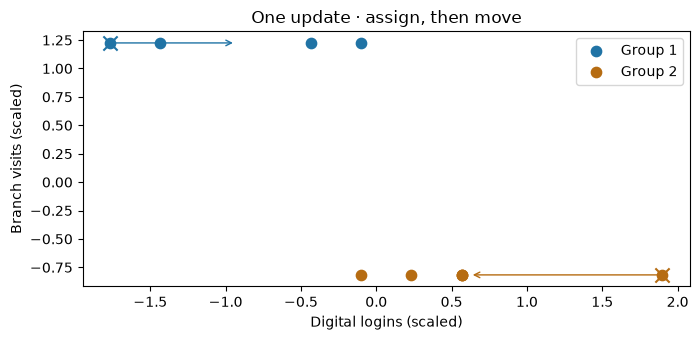

In [2]:
centres = points[[0, -1]]
distance_a = ((points - centres[0]) ** 2).sum(axis=1)
distance_b = ((points - centres[1]) ** 2).sum(axis=1)
group = np.where(distance_a <= distance_b, 0, 1)
moved = pd.DataFrame(points).groupby(group).mean().to_numpy()
fig, ax = plt.subplots(figsize=(7.1, 3.5))
for i, color in [(0, "#2073a5"), (1, "#b66c12")]:
    ax.scatter(*points[group == i].T, s=55, color=color, label=f"Group {i + 1}")
    ax.scatter(*centres[i], color=color, marker="x", s=105)
    ax.annotate("", xy=moved[i], xytext=centres[i], arrowprops={"arrowstyle": "->", "color": color})
ax.set(title="One update · assign, then move", xlabel="Digital logins (scaled)", ylabel="Branch visits (scaled)")
ax.legend()
plt.tight_layout()
plt.show()

## 2 · Try two, three, four or five groups

**What we’re doing.** Fit k-means with several counts on the same customers. Record how tightly points fit their centres and how well groups are separated.

**Why.** Inertia usually falls when we add groups. Silhouette also considers closeness to the next group. Both help us choose a count to discuss.

**Look for.** Look for a bend in inertia and stronger silhouette values. Then ask whether the resulting groups are useful and easy to describe.

In [3]:
sample = customers.sample(450, random_state=42)
scaled = StandardScaler().fit_transform(sample[features])
results = []
for k in [2, 3, 4, 5]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(scaled)
    results.append([k, model.inertia_, silhouette_score(scaled, model.labels_)])
display(pd.DataFrame(results, columns=["Groups (k)", "Inertia", "Silhouette"]).round(3))

,Groups (k),Inertia,Silhouette
0,2,547.769,0.421
1,3,339.517,0.431
2,4,243.757,0.492
3,5,173.570,0.519


**When k-means is a good fit.** It tends to work best with compact
groups of roughly similar size. Scaling helps when the input units
differ. The k-means++ starting rule spreads out the initial centres.
Repeating the fit with another seed helps check whether the groups stay
similar. In L3.2 we compare two fits on the same rows.

## 3 · Follow the closest groups as they merge

**What we’re doing.** Start with one customer per group, then merge nearby groups. Draw the merges as branches in a chart.

**Why.** Hierarchical clustering lets us see several possible groupings from one diagram. Choosing a horizontal cut says how far apart we allow groups to be before joining them.

**Look for.** Start from the leaves at the bottom. Higher joins represent larger separation under the chosen merge rule.

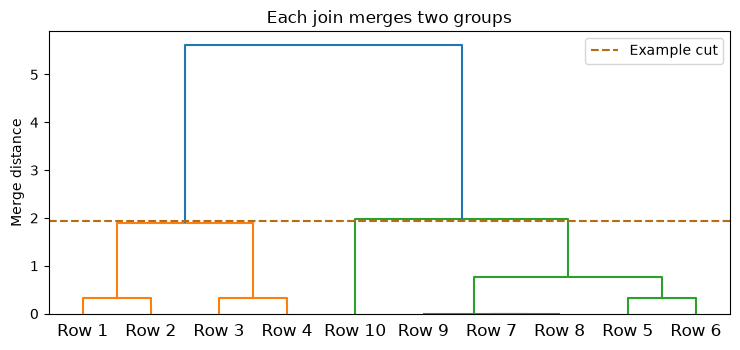

In [4]:
merges = linkage(points, method="ward")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
dendrogram(merges, labels=[f"Row {i}" for i in range(1, len(points) + 1)], ax=ax)
cut = (merges[-2, 2] + merges[-3, 2]) / 2
ax.axhline(cut, ls="--", color="#b66c12", label="Example cut")
ax.set(title="Each join merges two groups", ylabel="Merge distance")
ax.legend()
plt.tight_layout()
plt.show()

**How close are two groups?** Single linkage uses the closest pair.
Complete uses the farthest pair. Average uses the average distance.
Ward tries to keep points tightly grouped after the merge. This bottom-up
method is called agglomerative. A top-down method starts with one big
group and splits it. Use a small sample for the merge chart.

## 4 · Try one yes-or-no question on the loans

**What we’re doing.** Ask whether debt payments are at least 40% of income. Compare the mix of recorded defaults before the split and within each answer group.

**Why.** A tree searches for questions that make the answer groups less mixed. Gini is one number for how mixed a group is. Entropy is another.

**Look for.** For a yes-or-no answer, Gini is zero for a pure group and 0.5 for an even mix. The weighted after-split figure gives larger groups more say.

In [5]:
columns = ["debt_burden_ratio", "default_12m"]
loans = pd.read_csv(data / "loan_applications.csv", usecols=columns).dropna().sample(3000, random_state=42)
side = loans["debt_burden_ratio"] >= .40
groups = loans.groupby(side)["default_12m"].agg(["count", "mean"])
groups["Gini"] = 2 * groups["mean"] * (1 - groups["mean"])
overall = loans["default_12m"].mean()
display(groups.round(3))
print("Gini before:", round(2 * overall * (1 - overall), 4))
print("Gini after:", round((groups["count"] * groups["Gini"]).sum() / len(loans), 4))

,count,mean,Gini
debt_burden_ratio,,,
False,1539,0.049,0.094
True,1461,0.103,0.185


Gini before: 0.1399
Gini after: 0.1384


## 5 · Read the tree’s questions

**What we’re doing.** Let a short tree choose where to split the debt ratio rather than fixing the split at 40%.

**Why.** The tree picks the split that improves its own training score most at that point. Read the top question first, then follow the yes or no branch to a final guess.

**Look for.** The root is the first question and the leaves are the end points. This tree ends after at most two levels of questions.

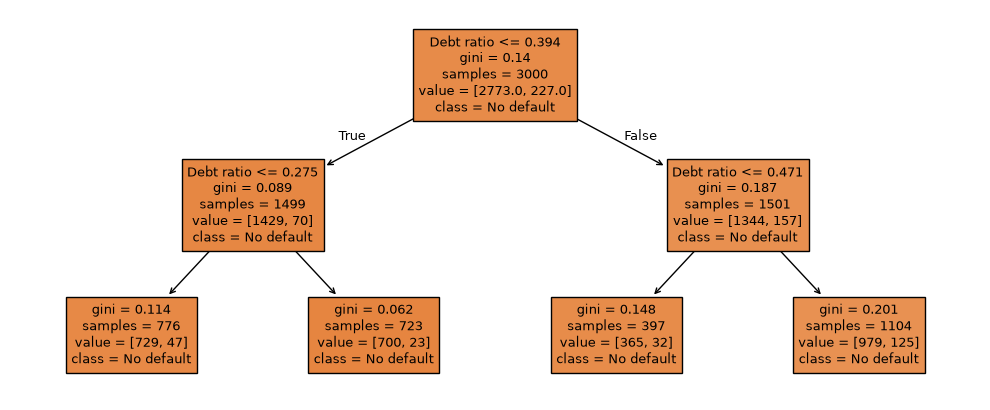

In [6]:
feature = ["debt_burden_ratio"]
tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=80, random_state=42)
tree.fit(loans[feature], loans["default_12m"])
fig, ax = plt.subplots(figsize=(10, 4.2))
plot_tree(tree, feature_names=["Debt ratio"], class_names=["No default", "Default"], filled=True, ax=ax, fontsize=9)
plt.tight_layout()
plt.show()

### Your turn

Which of the two methods needed recorded answers? Point to one place where k-means uses distance and one where the tree counts a mix of labels.